Upload population_philippines_annual_2000_2025_cleaned.xlsx


Saving population_philippines_annual_2000_2025.xlsx to population_philippines_annual_2000_2025.xlsx

Original dataset shape: (520, 4)
   Year  Region  Population                         Data Type
0  2000  Region      2000.0                 Source checkpoint
1  2001  Region      2001.0  Linear interpolation (2000-2005)
2  2002  Region      2002.0  Linear interpolation (2000-2005)
3  2003  Region      2003.0  Linear interpolation (2000-2005)
4  2004  Region      2004.0  Linear interpolation (2000-2005)

Cleaned dataset shape: (495, 4)

Missing values:
Year          0
Region        0
Population    0
dtype: int64

Year range: 2000 - 2025
Number of regions: 20

Original records: 495
Expanded quarterly records: 1920
Additional estimated records: 1425


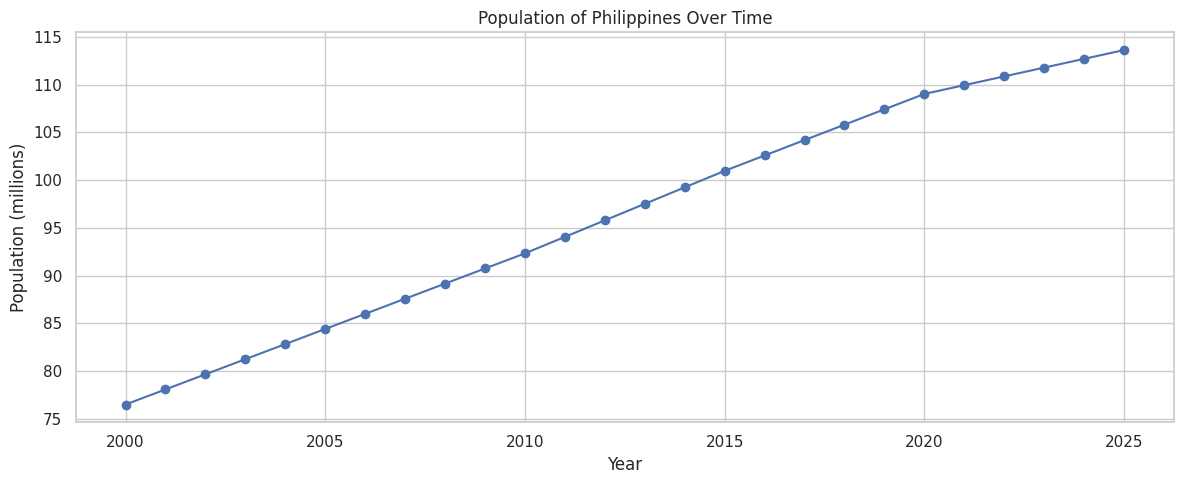

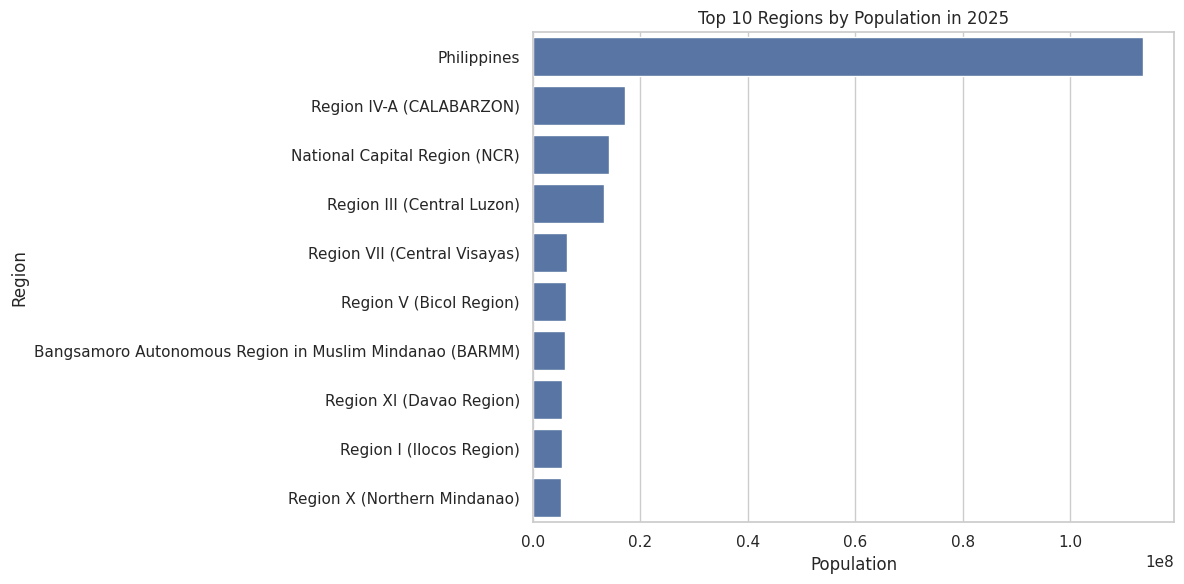

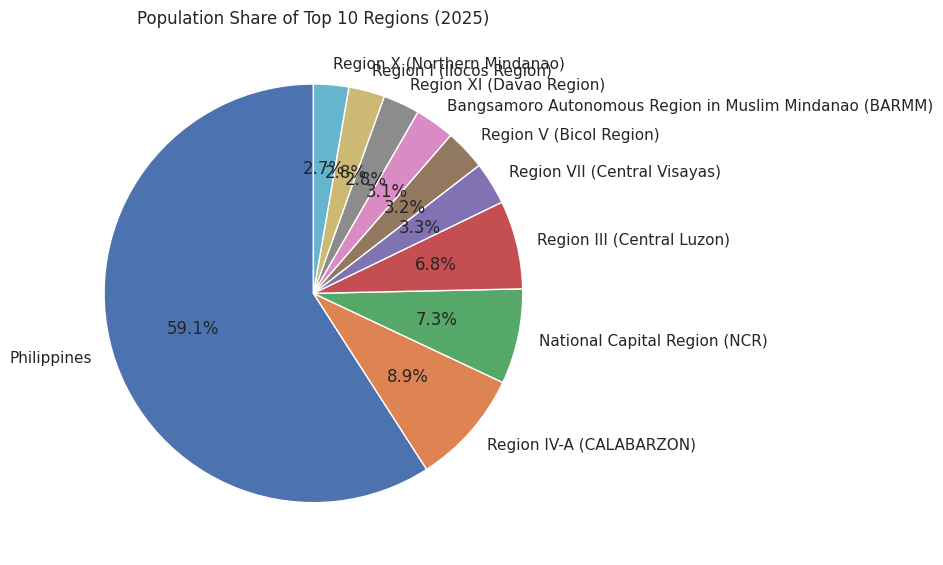

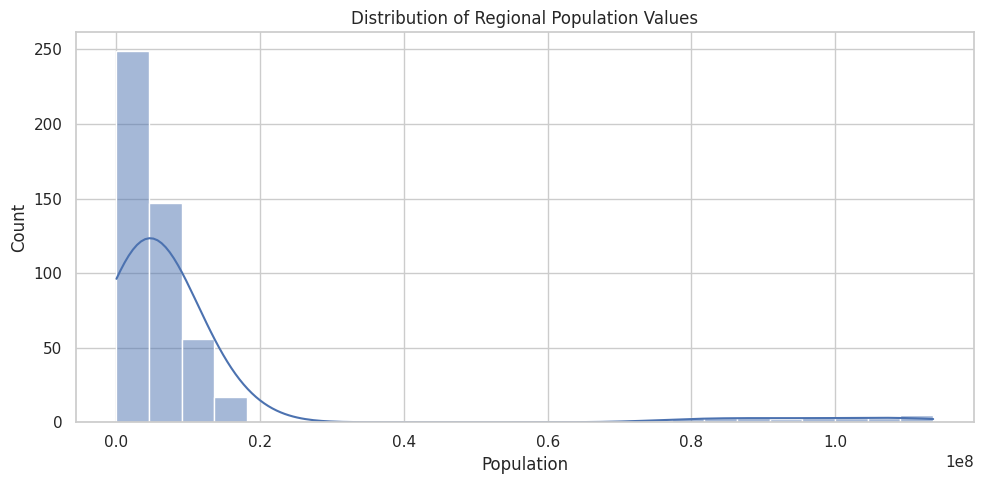

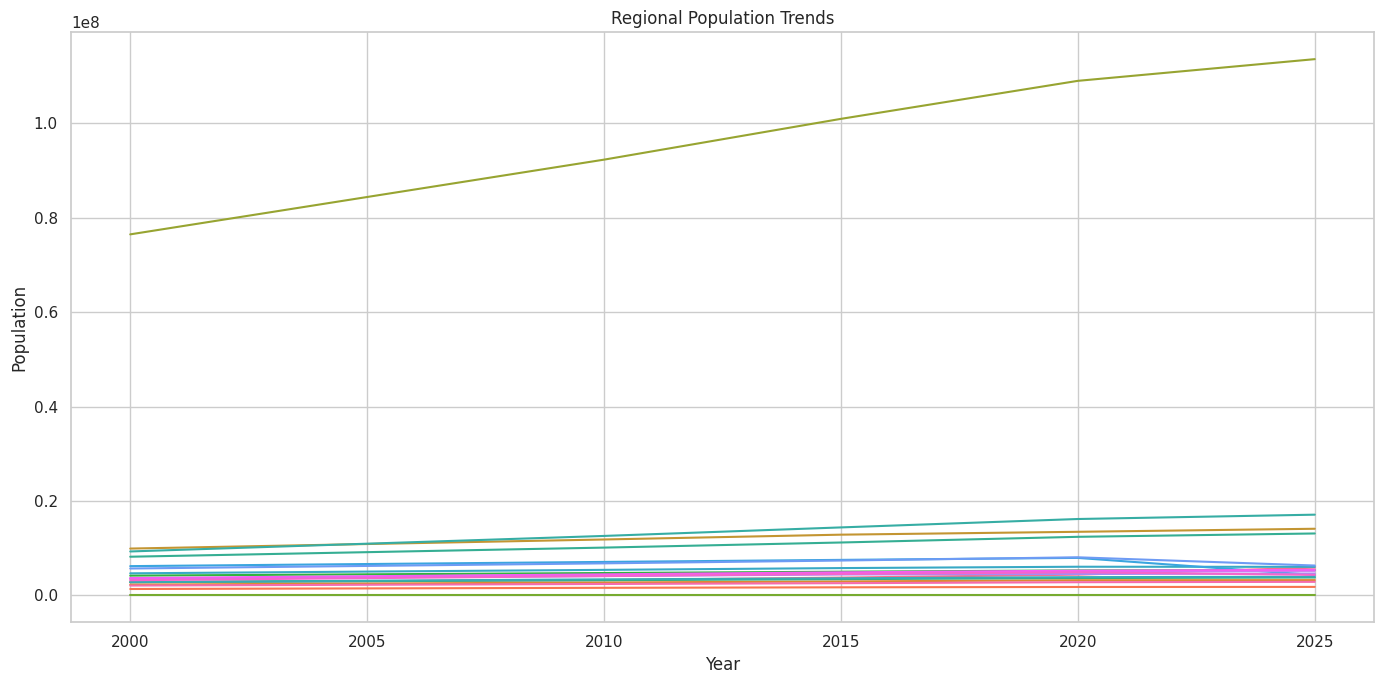


DESCRIPTIVE STATISTICS
count    4.950000e+02
mean     1.009212e+07
std      2.079362e+07
min      2.000000e+03
25%      3.199196e+06
50%      4.545276e+06
75%      7.173719e+06
max      1.136313e+08
Name: Population, dtype: float64

Training years: 2000 - 2022
Testing years: 2023 - 2025
Training records: 1748
Testing records: 172

Linear Regression
MAE:  2,367,785.03
RMSE: 4,071,174.40
R²:   0.9715


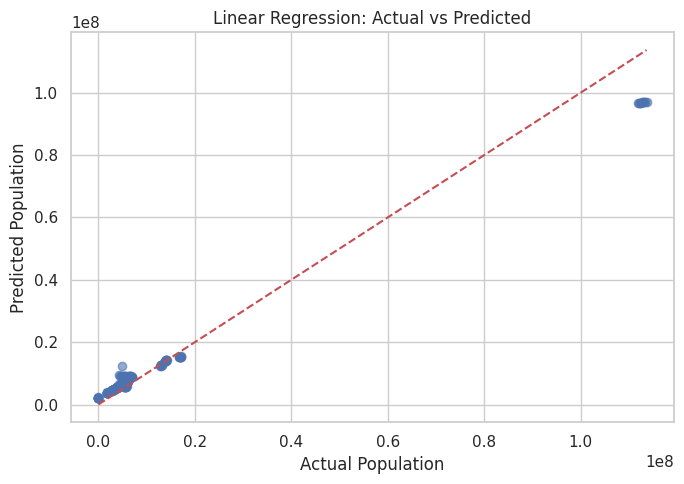


Random Forest Regressor
MAE:  278,862.37
RMSE: 549,103.91
R²:   0.9995


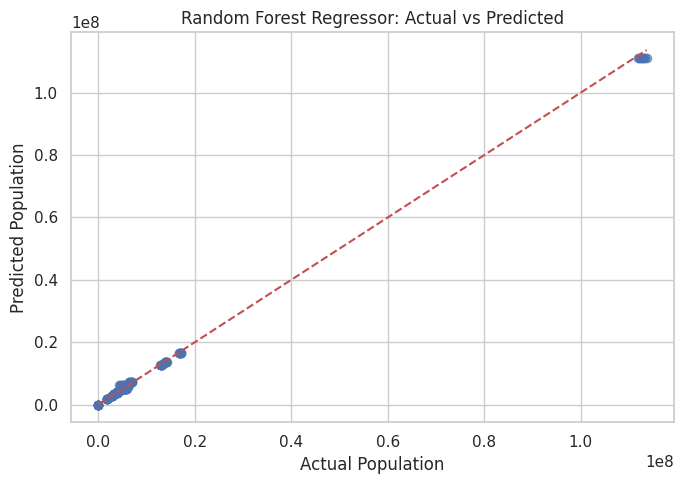


Logistic Regression
Accuracy:  90.70%
Precision: 0.9070
Recall:    1.0000
F1 Score:  0.9512
ROC AUC:   0.0008

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        16
           1       0.91      1.00      0.95       156

    accuracy                           0.91       172
   macro avg       0.45      0.50      0.48       172
weighted avg       0.82      0.91      0.86       172



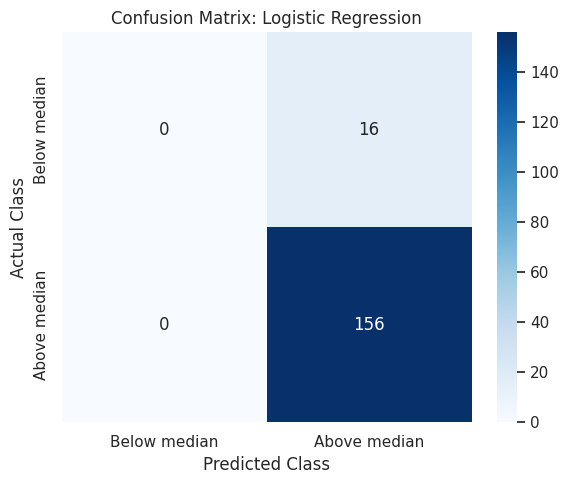


Random Forest Classifier
Accuracy:  95.93%
Precision: 0.9571
Recall:    1.0000
F1 Score:  0.9781
ROC AUC:   0.7989

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.56      0.72        16
           1       0.96      1.00      0.98       156

    accuracy                           0.96       172
   macro avg       0.98      0.78      0.85       172
weighted avg       0.96      0.96      0.95       172



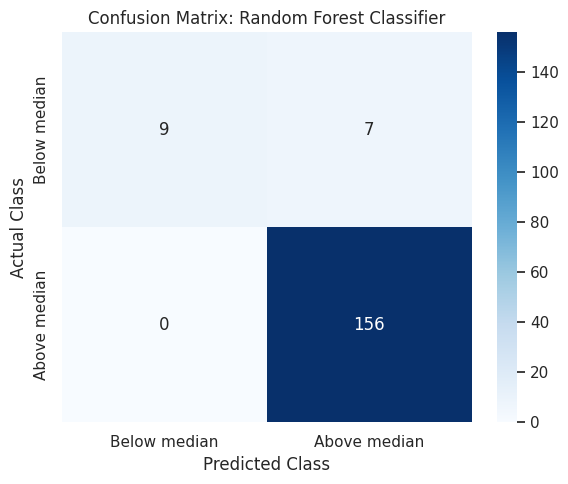

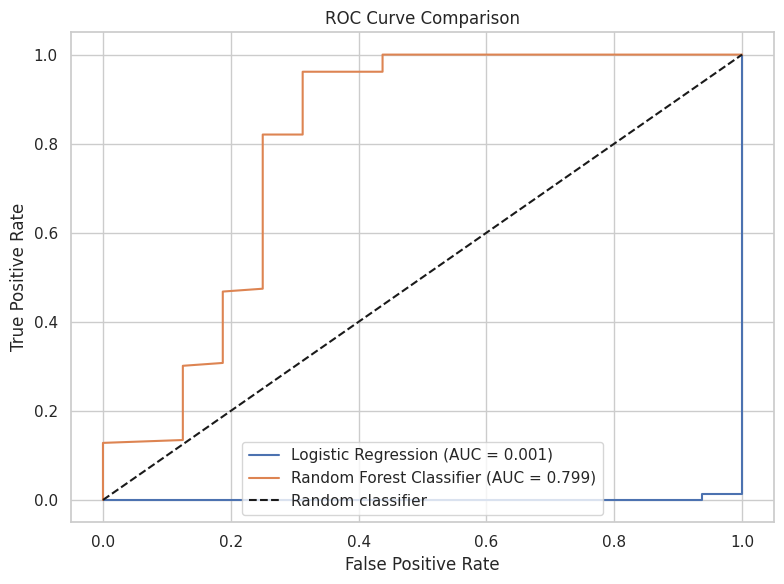


MODEL COMPARISON TABLE
                   Model           Task          MAE         RMSE     R2  Accuracy  Precision  Recall  F1 Score  ROC AUC
       Linear Regression     Regression 2367785.0255 4071174.4013 0.9715       NaN        NaN     NaN       NaN      NaN
 Random Forest Regressor     Regression  278862.3695  549103.9083 0.9995       NaN        NaN     NaN       NaN      NaN
     Logistic Regression Classification          NaN          NaN    NaN    0.9070     0.9070     1.0    0.9512   0.0008
Random Forest Classifier Classification          NaN          NaN    NaN    0.9593     0.9571     1.0    0.9781   0.7989

BEST CLASSIFICATION MODEL: Random Forest Classifier
Accuracy: 95.93%
Target achieved: classification accuracy is at least 80%.

Files created:
1. expanded_population_dataset.csv
2. model_comparison_results.csv
3. population_analysis_results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# PHILIPPINE POPULATION DATA ANALYTICS AND MACHINE LEARNING
# 1. Descriptive Analytics
# 2. Four Prediction Models
# 3. ROC Curves and Confusion Matrices
# 4. Model Comparison Table
# 5. Increase Records Using Quarterly Interpolation
# ============================================================

!pip -q install openpyxl scikit-learn seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid")
np.random.seed(42)

# ============================================================
# STEP 1: UPLOAD AND LOAD DATASET
# ============================================================

print("Upload population_philippines_annual_2000_2025_cleaned.xlsx")
uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_excel(filename, sheet_name="Annual Long Format")

print("\nOriginal dataset shape:", df.shape)
print(df.head())

# ============================================================
# STEP 2: CLEAN DATA
# ============================================================

df.columns = df.columns.astype(str).str.strip()
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df["Population"] = pd.to_numeric(df["Population"], errors="coerce")
df["Region"] = df["Region"].astype("string").str.strip()

df = df.dropna(subset=["Year", "Region", "Population"])
df = df[df["Population"] > 0].copy()
df["Year"] = df["Year"].astype(int)

df = df.drop_duplicates(subset=["Year", "Region"])
df = df.sort_values(["Region", "Year"]).reset_index(drop=True)

print("\nCleaned dataset shape:", df.shape)
print("\nMissing values:")
print(df[["Year", "Region", "Population"]].isnull().sum())

print("\nYear range:", df["Year"].min(), "-", df["Year"].max())
print("Number of regions:", df["Region"].nunique())

# ============================================================
# STEP 3: INCREASE RECORDS USING QUARTERLY INTERPOLATION
# NOTE: These are synthetic estimates, NOT official observations.
# ============================================================

quarterly_data = []

for region, group in df.groupby("Region"):
    group = group.sort_values("Year")

    annual_series = group.set_index("Year")["Population"]
    full_years = range(int(annual_series.index.min()),
                       int(annual_series.index.max()) + 1)

    annual_series = annual_series.reindex(full_years).interpolate(
        method="linear", limit_direction="both"
    )

    for year, population in annual_series.items():
        quarterly_data.append({
            "Year": year,
            "Quarter": 1,
            "Region": region,
            "Population": population,
            "Data Type": "Quarterly interpolation estimate"
        })

        # Create quarterly estimates for Q2, Q3, and Q4
        next_population = annual_series.get(year + 1, np.nan)

        for quarter in [2, 3, 4]:
            if pd.notna(next_population):
                fraction = (quarter - 1) / 4
                estimated_population = (
                    population +
                    fraction * (next_population - population)
                )
            else:
                # No extrapolation beyond the final available year
                estimated_population = np.nan

            if pd.notna(estimated_population):
                quarterly_data.append({
                    "Year": year,
                    "Quarter": quarter,
                    "Region": region,
                    "Population": estimated_population,
                    "Data Type": "Synthetic quarterly estimate"
                })

expanded_df = pd.DataFrame(quarterly_data)
expanded_df = expanded_df.dropna(subset=["Population"])
expanded_df["Time"] = (
    expanded_df["Year"] + (expanded_df["Quarter"] - 1) / 4
)

print("\nOriginal records:", len(df))
print("Expanded quarterly records:", len(expanded_df))
print("Additional estimated records:", len(expanded_df) - len(df))

expanded_df.to_csv("expanded_population_dataset.csv", index=False)

# ============================================================
# STEP 4: DESCRIPTIVE ANALYTICS
# ============================================================

# A. Philippine population trend (sum of regions is not necessarily
# the official national total; use the supplied national row if present)

national_rows = df[
    df["Region"].str.contains("Philippines|National Total", case=False,
                              regex=True, na=False)
]

if len(national_rows) > 0:
    trend = national_rows.groupby("Year")["Population"].sum()
    trend_label = "Population of Philippines"
else:
    trend = df.groupby("Year")["Population"].sum()
    trend_label = "Sum of regional population estimates"

plt.figure(figsize=(12, 5))
plt.plot(trend.index, trend.values / 1_000_000, marker="o")
plt.title(trend_label + " Over Time")
plt.xlabel("Year")
plt.ylabel("Population (millions)")
plt.tight_layout()
plt.show()

# B. Top 10 regions by population in the latest year

latest_year = df["Year"].max()
latest = df[df["Year"] == latest_year].sort_values(
    "Population", ascending=False
).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=latest, x="Population", y="Region")
plt.title(f"Top 10 Regions by Population in {latest_year}")
plt.xlabel("Population")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

# C. Pie chart of population share in latest year
plt.figure(figsize=(9, 9))
plt.pie(
    latest["Population"],
    labels=latest["Region"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title(f"Population Share of Top 10 Regions ({latest_year})")
plt.tight_layout()
plt.show()

# D. Population distribution
plt.figure(figsize=(10, 5))
sns.histplot(df["Population"], bins=25, kde=True)
plt.title("Distribution of Regional Population Values")
plt.xlabel("Population")
plt.tight_layout()
plt.show()

# E. Population by region over time
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=df, x="Year", y="Population",
    hue="Region", legend=False
)
plt.title("Regional Population Trends")
plt.tight_layout()
plt.show()

# Descriptive statistics
print("\nDESCRIPTIVE STATISTICS")
print(df["Population"].describe())

# ============================================================
# STEP 5: PREPARE MACHINE LEARNING DATA
# Models predict population from region and time.
# Use a chronological split to reduce time leakage.
# ============================================================

# Use quarterly records for greater time resolution.
# Train on earlier dates; test on later dates.
model_df = expanded_df.copy()

# Classification target: population above/below each region's
# median population in the supplied annual dataset.
region_medians = df.groupby("Region")["Population"].median()

model_df["Above_Region_Median"] = (
    model_df["Population"] >
    model_df["Region"].map(region_medians)
).astype(int)

# Exclude the actual population from features to prevent target leakage.
features = ["Year", "Quarter", "Region"]
target_reg = "Population"
target_cls = "Above_Region_Median"

cutoff_year = 2022

train = model_df[model_df["Year"] <= cutoff_year].copy()
test = model_df[model_df["Year"] > cutoff_year].copy()

if train.empty or test.empty:
    raise ValueError("Not enough records for chronological train/test split.")

X_train = train[features]
X_test = test[features]

y_train_reg = train[target_reg]
y_test_reg = test[target_reg]

y_train_cls = train[target_cls]
y_test_cls = test[target_cls]

print("\nTraining years:", train["Year"].min(), "-", train["Year"].max())
print("Testing years:", test["Year"].min(), "-", test["Year"].max())
print("Training records:", len(train))
print("Testing records:", len(test))

# Preprocessing for numeric and categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), ["Year", "Quarter"]),
        ("region", OneHotEncoder(handle_unknown="ignore"),
         ["Region"])
    ]
)

# ============================================================
# STEP 6: FOUR MACHINE LEARNING MODELS
# Models 1 and 2: Regression
# Models 3 and 4: Classification
# ============================================================

regression_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=200, random_state=42, min_samples_leaf=2
    )
}

classification_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced"
    ),
    "Random Forest Classifier": RandomForestClassifier(
        n_estimators=200, random_state=42,
        class_weight="balanced", min_samples_leaf=2
    )
}

regression_results = []
classification_results = []
trained_classifiers = {}

# ---------------- REGRESSION MODELS ----------------

for name, algorithm in regression_models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    model.fit(X_train, y_train_reg)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test_reg, predictions)
    rmse = np.sqrt(mean_squared_error(y_test_reg, predictions))
    r2 = r2_score(y_test_reg, predictions)

    regression_results.append({
        "Model": name,
        "Task": "Regression",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Accuracy": np.nan,
        "Precision": np.nan,
        "Recall": np.nan,
        "F1 Score": np.nan,
        "ROC AUC": np.nan
    })

    print(f"\n{name}")
    print(f"MAE:  {mae:,.2f}")
    print(f"RMSE: {rmse:,.2f}")
    print(f"R²:   {r2:.4f}")

    plt.figure(figsize=(7, 5))
    plt.scatter(y_test_reg, predictions, alpha=0.6)
    lower = min(y_test_reg.min(), predictions.min())
    upper = max(y_test_reg.max(), predictions.max())
    plt.plot([lower, upper], [lower, upper], "r--")
    plt.xlabel("Actual Population")
    plt.ylabel("Predicted Population")
    plt.title(f"{name}: Actual vs Predicted")
    plt.tight_layout()
    plt.show()

# ---------------- CLASSIFICATION MODELS ----------------

for name, algorithm in classification_models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    model.fit(X_train, y_train_cls)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test_cls, predictions)
    precision = precision_score(
        y_test_cls, predictions, zero_division=0
    )
    recall = recall_score(
        y_test_cls, predictions, zero_division=0
    )
    f1 = f1_score(y_test_cls, predictions, zero_division=0)

    # ROC AUC requires both classes in the test set.
    if y_test_cls.nunique() == 2:
        auc = roc_auc_score(y_test_cls, probabilities)
    else:
        auc = np.nan
        print("ROC AUC unavailable: test set contains only one class.")

    classification_results.append({
        "Model": name,
        "Task": "Classification",
        "MAE": np.nan,
        "RMSE": np.nan,
        "R2": np.nan,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": auc
    })

    trained_classifiers[name] = model

    print(f"\n{name}")
    print(f"Accuracy:  {accuracy:.2%}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"ROC AUC:   {auc:.4f}" if pd.notna(auc)
          else "ROC AUC: unavailable")

    print("\nClassification Report:")
    print(classification_report(
        y_test_cls, predictions, zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(y_test_cls, predictions, labels=[0, 1])

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Below median", "Above median"],
        yticklabels=["Below median", "Above median"]
    )
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.title(f"Confusion Matrix: {name}")
    plt.tight_layout()
    plt.show()

# ============================================================
# STEP 7: ROC CURVE
# ============================================================

plt.figure(figsize=(8, 6))
roc_plotted = False

for name, model in trained_classifiers.items():
    probabilities = model.predict_proba(X_test)[:, 1]

    if y_test_cls.nunique() == 2:
        fpr, tpr, _ = roc_curve(y_test_cls, probabilities)
        auc = roc_auc_score(y_test_cls, probabilities)
        plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
        roc_plotted = True

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
if roc_plotted:
    plt.show()
else:
    plt.close()
    print("ROC curves cannot be calculated for a one-class test set.")

# ============================================================
# STEP 8: COMPARISON TABLE FOR ALL FOUR MODELS
# ============================================================

results = pd.DataFrame(regression_results + classification_results)

print("\nMODEL COMPARISON TABLE")
print(results.round(4).to_string(index=False))

results.to_csv("model_comparison_results.csv", index=False)

# Compare classification accuracy
cls_results = results[results["Task"] == "Classification"].copy()

if not cls_results.empty:
    best_idx = cls_results["Accuracy"].idxmax()
    best = cls_results.loc[best_idx]

    print("\nBEST CLASSIFICATION MODEL:", best["Model"])
    print(f"Accuracy: {best['Accuracy']:.2%}")

    if best["Accuracy"] >= 0.80:
        print("Target achieved: classification accuracy is at least 80%.")
    else:
        print(
            "Target not achieved: accuracy is below 80%. "
            "Do not artificially alter the test data to raise accuracy."
        )

# ============================================================
# STEP 9: EXPORT DATA AND RESULTS
# ============================================================

with pd.ExcelWriter("population_analysis_results.xlsx") as writer:
    df.to_excel(writer, sheet_name="Clean Annual Data", index=False)
    expanded_df.to_excel(
        writer, sheet_name="Expanded Quarterly Data", index=False
    )
    results.to_excel(writer, sheet_name="Model Comparison", index=False)

print("\nFiles created:")
print("1. expanded_population_dataset.csv")
print("2. model_comparison_results.csv")
print("3. population_analysis_results.xlsx")

files.download("population_analysis_results.xlsx")
files.download("model_comparison_results.csv")
